# Chapitre 8 - Cours 1 : Curation des données

Un modèle ne vaut que ce que valent ses données d'entraînement : même avec un calcul
illimité, une équipe ne peut pas affiner un bon modèle sans bonnes données. Le chapitre 8
du livre traite de l'**ingénierie des données** (« dataset engineering ») : construire le
jeu de données qui permet d'entraîner le meilleur modèle possible dans un budget donné.

Ce premier notebook couvre l'introduction du chapitre et la section *Data Curation* :

1. la vision **centrée sur les données** (encadré *A Data-Centric View of AI*) ;
2. **quelles données** pour quelle phase d'entraînement (formats, chaîne de pensée, outils) ;
3. la **qualité** des données (section *Data Quality*), avec une expérience sur le bruit
   d'étiquetage ;
4. la **couverture** et la diversité (section *Data Coverage*), mesurées et expérimentées ;
5. la **quantité** (section *Data Quantity*) : courbes d'apprentissage, loi de puissance,
   budget ;
6. l'**acquisition et l'annotation** (section *Data Acquisition and Annotation*) :
   entonnoir de constitution, consignes, accord inter-annotateurs (kappas de Cohen et de
   Fleiss implémentés).

Pour isoler les effets étudiés, on utilise un « petit monde » contrôlé : un problème de
classification synthétique où l'on connaît la vérité terrain, et un classifieur rapide
(SVM). Les conclusions qualitatives se transposent à l'affinage des LLM, que l'on ne
peut pas réentraîner des dizaines de fois dans un notebook.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.svm import SVC

from aie import ch08_donnees as d8
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

warnings.filterwarnings("ignore")
set_style()
plt.rcParams["mathtext.fontset"] = "dejavusans"  # glyphes complets pour les exposants des axes log
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)


def titre(ax, texte, sous_titre):
    """Titre d'axe suivi d'un sous-titre gris (le titre est décalé pour lui laisser la place)."""
    ax.set_title(texte, pad=18)
    subtitle(ax, sous_titre)

## 1. Une vision centrée sur les données (section *A Data-Centric View of AI*)

**Le problème.** Pendant des années, la recherche en apprentissage profond a été
**centrée sur le modèle** : on fixe un jeu de données (ImageNet...) et l'on cherche la
meilleure architecture, la meilleure technique d'entraînement. Or, aujourd'hui, peu
d'entreprises entraînent des modèles de fondation à partir de zéro : elles partent toutes
des mêmes modèles ouverts ou des mêmes API. **Ce qui les différencie, ce sont leurs
données.**

L'approche **centrée sur les données** inverse la question : *à modèle fixé, quel jeu de
données donne les meilleures performances ?* Le livre cite des compétitions construites
sur ce principe (le concours d'Andrew Ng en 2021, DataComp en 2023 où un script
d'entraînement standard évalue chaque jeu de données soumis sur 38 tâches). Il note
aussi que le nombre de personnes créditées pour le travail sur les données est passé
d'une poignée pour GPT-3 à environ quatre-vingts pour GPT-4.

**Intuition culinaire** (reprise par le livre) : entraîner un modèle, c'est cuisiner.
La **qualité** des données est la fraîcheur des ingrédients, la **couverture** est
l'équilibre de la recette, la **quantité** est le volume d'ingrédients. Ce sont les trois
critères qui structurent la curation.

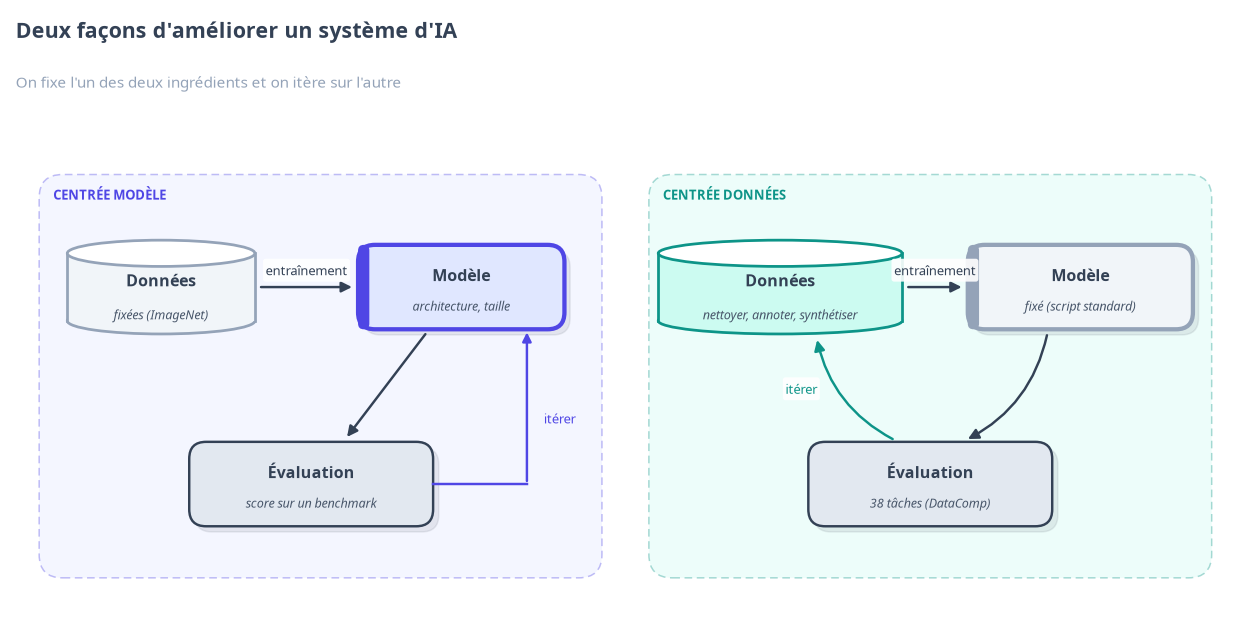

In [2]:
d = Diagram(13, 5.4, title="Deux façons d'améliorer un système d'IA",
            subtitle="On fixe l'un des deux ingrédients et on itère sur l'autre")
d.group(0.3, 0.3, 6.3, 4.6, "centrée modèle", color=INDIGO)
d.box("D1", 1.6, 3.4, "Données", sub="fixées (ImageNet)", color=GRAY, kind="db", w=2.0, h=1.0)
d.box("M1", 4.8, 3.4, "Modèle", sub="architecture, taille", color=INDIGO, kind="model", w=2.2)
d.box("E1", 3.2, 1.3, "Évaluation", sub="score sur un benchmark", color=SLATE, w=2.6)
d.arrow("D1", "M1", "entraînement")
d.arrow("M1", "E1")
d.line([(4.5, 1.3), (5.5, 1.3), (5.5, 2.95)], color=INDIGO, style="solid", lw=1.6)
d.note(5.85, 2.0, "itérer", color=INDIGO, fontsize=8.5, style="normal")
d.group(6.8, 0.3, 12.8, 4.6, "centrée données", color=TEAL)
d.box("M2", 11.4, 3.4, "Modèle", sub="fixé (script standard)", color=GRAY, kind="model", w=2.4)
d.box("D2", 8.2, 3.4, "Données", sub="nettoyer, annoter, synthétiser", color=TEAL, kind="db", w=2.6, h=1.0)
d.box("E2", 9.8, 1.3, "Évaluation", sub="38 tâches (DataComp)", color=SLATE, w=2.6)
d.arrow("D2", "M2", "entraînement")
d.arrow("M2", "E2", rad=-0.25)
d.arrow("E2", "D2", "itérer", color=TEAL, rad=-0.25, label_offset=(-0.45, 0.1))
d.show()

Le livre souligne que cette dichotomie guide la recherche mais qu'en pratique les
progrès viennent des deux. Pour un ingénieur d'application, en revanche, le levier
« données » est souvent le seul disponible : on ne modifie pas l'architecture de Qwen ou
de Llama, mais on choisit **ce qu'on lui montre**.

> **À retenir.** L'IA centrée sur les données cherche le meilleur jeu de données à
> modèle fixé. Comme les modèles de base sont largement partagés, les données sont
> devenues le principal facteur de différenciation, et un métier à part entière.

## 2. Quelles données pour quel entraînement ? (section *Data Curation*)

Les données à collecter dépendent de **ce que l'on veut apprendre au modèle**, donc de
la phase d'entraînement. Le livre distingue quatre formats :

| Phase | Format d'un exemple | Unité de quantité |
|---|---|---|
| Affinage auto-supervisé | une séquence de texte | tokens |
| Affinage sur instructions (SFT) | (instruction, réponse) | exemples |
| Affinage par préférences | (instruction, réponse gagnante, réponse perdante) | comparaisons |
| Modèle de récompense | idem, ou ((instruction, réponse), score) | exemples notés |

Le chapitre se concentre sur les données de **post-entraînement**, les plus utiles aux
développeurs d'applications. Voici un enregistrement de chaque type.

In [3]:
exemples = {
    "auto-supervisé": {"text": "Le contrat de bail est conclu pour une durée de trois ans..."},
    "SFT": {"instruction": "Résume ce bail en une phrase.",
            "response": "Bail de trois ans, loyer mensuel de 900 euros, préavis de trois mois."},
    "préférence": {"instruction": "Résume ce bail en une phrase.",
                   "chosen": "Bail de trois ans, loyer de 900 euros par mois.",
                   "rejected": "Ce document est un bail. Il contient des clauses."},
    "récompense": {"instruction": "Résume ce bail en une phrase.",
                   "response": "Ce document est un bail.", "score": 2},
}
pd.DataFrame({k: [str(v)] for k, v in exemples.items()}).T.rename(columns={0: "exemple (dict JSON)"})

,exemple (dict JSON)
auto-supervisé,{'text': 'Le contrat de bail est conclu pour une durée de trois ans...'}
SFT,"{'instruction': 'Résume ce bail en une phrase.', 'response': 'Bail de trois ans, loyer..."
préférence,"{'instruction': 'Résume ce bail en une phrase.', 'chosen': 'Bail de trois ans, loyer d..."
récompense,"{'instruction': 'Résume ce bail en une phrase.', 'response': 'Ce document est un bail...."


### Comportements complexes : chaîne de pensée et usage d'outils

Les données d'entraînement doivent **montrer le comportement voulu**. C'est facile pour
une réponse courte, beaucoup plus coûteux pour deux comportements complexes :

- **la chaîne de pensée** (CoT, chapitre 5) : pour qu'un modèle apprenne à raisonner pas
  à pas, ses données doivent contenir des réponses détaillées. Le livre cite des travaux
  où l'ajout de telles réponses dans l'affinage double presque l'exactitude sur certaines
  tâches de raisonnement. Mais écrire un raisonnement complet coûte bien plus cher
  qu'écrire la réponse finale ;
- **l'usage d'outils** : les experts humains oublient d'expliciter des étapes et, surtout,
  ce qui est efficace pour un humain (cliquer dans un navigateur) ne l'est pas pour un
  modèle (appeler une API). D'où le recours à la simulation et à la synthèse (cours 2).
  Ces données exigent aussi des formats spéciaux : Llama 3 utilise des en-têtes qui
  indiquent la source et la destination de chaque message (utilisateur, interpréteur
  de code...).

Mesurons le surcoût d'annotation de la chaîne de pensée en tokens, sur un exemple de
notre cru, avec le tokenizer de Qwen2.5.

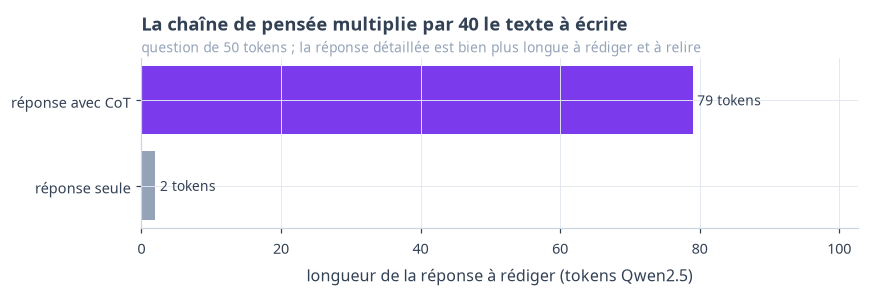

In [4]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(llm.SMALL)
question = ("Un cinéma compte 120 places. 47 spectateurs entrent à 20 h, 18 sortent à l'entracte "
            "et 25 arrivent ensuite. Combien de places restent libres ?")
sans_cot = "64"
avec_cot = ("Au départ, 47 spectateurs sont dans la salle. À l'entracte, 18 sortent : 47 - 18 = 29. "
            "Puis 25 arrivent : 29 + 25 = 54 spectateurs. Il reste donc 120 - 54 = 66 places libres.")
n_q, n_a, n_c = (len(tok(t)["input_ids"]) for t in (question, sans_cot, avec_cot))

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(["réponse seule", "réponse avec CoT"], [n_a, n_c], color=[GRAY, VIOLET])
annotate_bars(ax, "{:.0f} tokens")
ax.set_xlabel("longueur de la réponse à rédiger (tokens Qwen2.5)")
titre(ax, f"La chaîne de pensée multiplie par {n_c / n_a:.0f} le texte à écrire",
      f"question de {n_q} tokens ; la réponse détaillée est bien plus longue à rédiger et à relire")
ax.set_xlim(0, n_c * 1.3)
finish(fig)
plt.show()

Remarquez que la « réponse seule » ci-dessus (64) est **fausse** : 120 - 54 = 66. La
réponse détaillée, elle, se vérifie ligne à ligne. C'est un argument supplémentaire en
faveur des données CoT : elles sont plus faciles à **contrôler**, pour un annotateur
comme pour un vérificateur automatique.

### Un tour ou plusieurs ? Ajouter ou retirer ?

- Les données **à un tour** apprennent à répondre à une instruction isolée ; les données
  **multi-tours** apprennent à mener une tâche (clarifier l'intention, intégrer une
  correction). Elles sont plus rares car il faut des scénarios dédiés.
- La curation sert aussi à **désapprendre** : si un assistant ajoute des réécritures non
  sollicitées quand on lui demande seulement de vérifier un fait, on cherche les exemples
  d'entraînement qui montrent ce comportement, on les **retire**, et l'on en ajoute qui
  montrent le comportement attendu.

> **À retenir.** Le format des données découle de la phase d'entraînement : séquences,
> paires (instruction, réponse), triplets de préférence ou exemples notés. Les
> comportements complexes (raisonnement, outils, multi-tours) coûtent beaucoup plus cher à
> annoter, ce qui pousse vers la synthèse.

## 3. Qualité des données (section *Data Quality*)

**Le constat.** Peu de données de grande qualité battent souvent beaucoup de données
bruitées. Le livre cite les créateurs de Yi (10 000 instructions soignées valent mieux
que des centaines de milliers d'instructions bruitées) et LIMA (1 000 exemples
soigneusement choisis suffisent à rendre un Llama 65B compétitif, avec une robustesse
moindre que les modèles de production).

**Qu'est-ce qu'une donnée de qualité ?** Le livre retient six caractéristiques :

| Critère | Question à se poser | Exemple de défaut |
|---|---|---|
| **Pertinente** | L'exemple concerne-t-il la tâche ? | jurisprudence du XIXe siècle pour du droit actuel |
| **Alignée sur la tâche** | L'annotation fait-elle ce que la tâche exige ? | réponse longue alors qu'on veut de la concision |
| **Cohérente** | Deux annotateurs donneraient-ils la même chose ? | une note de 3 qui vaut un 4 ailleurs |
| **Bien formatée** | Le format est-il celui attendu par le modèle ? | balises HTML, espaces parasites |
| **Suffisamment unique** | Y a-t-il des doublons ? | le même exemple répété cent fois |
| **Conforme** | Respecte-t-elle lois et politiques internes ? | données personnelles (PII) |

Le livre préfère « alignée » à « exacte » : selon la tâche, la réponse attendue n'est pas
toujours la plus exacte (créativité, concision...). Les critères « bien formatée » et
« unique » sont traités au cours 3 ; ici, nous étudions la **cohérence**, via le bruit
d'étiquetage.

### Le petit monde expérimental

Quatre classes (pensez à quatre intentions d'utilisateur), chacune formée de trois
sous-populations (trois façons d'exprimer cette intention), en dimension 10. Le jeu de
test, propre, est tiré autour des mêmes centres.

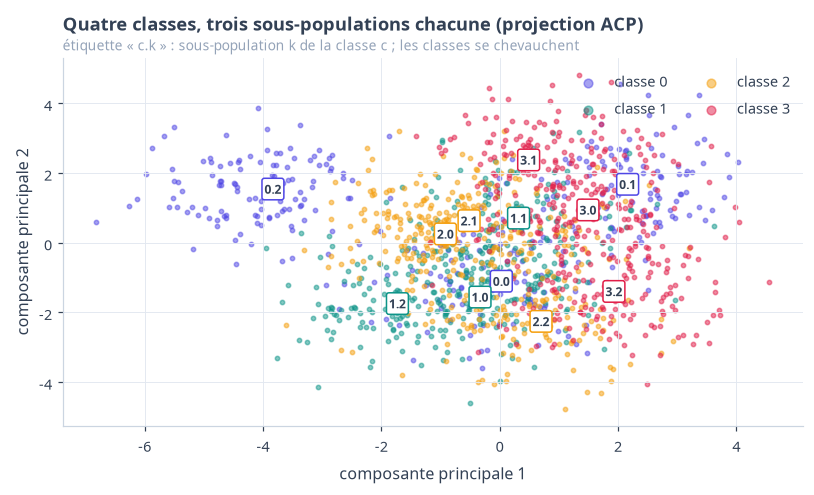

In [5]:
K, S, DIM, SEP = 4, 3, 10, 1.0
X, y, s, centres = d8.make_subpop_data(8000, n_classes=K, n_subpops=S, dim=DIM, sep=SEP, seed=0)
Xt, yt, st, _ = d8.make_subpop_data(3000, n_classes=K, n_subpops=S, dim=DIM, sep=SEP, seed=1, centers=centres)


def score(Xa, ya):
    """Exactitude sur le jeu de test propre d'un SVM (noyau RBF) entraîné sur (Xa, ya)."""
    return SVC().fit(Xa, ya).score(Xt, yt)


from sklearn.decomposition import PCA

P = PCA(2, random_state=0).fit(X)
Z = P.transform(X[:1500])
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for k in range(K):
    m = y[:1500] == k
    ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, color=COLORS[k], label=f"classe {k}")
Cz = P.transform(centres)
for g, (cx, cy) in enumerate(Cz):
    ax.text(cx, cy, f"{g // S}.{g % S}", fontsize=8, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=COLORS[g // S]))
ax.set_xlabel("composante principale 1"); ax.set_ylabel("composante principale 2")
titre(ax, "Quatre classes, trois sous-populations chacune (projection ACP)",
      "étiquette « c.k » : sous-population k de la classe c ; les classes se chevauchent")
ax.legend(loc="upper right", ncol=2, markerscale=2)
finish(fig)
plt.show()

### Deux sortes de bruit

On corrompt une fraction $\varepsilon$ des étiquettes d'entraînement de deux façons :

- **bruit symétrique** : la mauvaise étiquette est tirée au hasard parmi les $K-1$ autres
  (erreurs d'inattention) ;
- **bruit systématique** : toutes les erreurs vont vers la même classe (un annotateur qui
  a mal compris une consigne, ou une consigne ambiguë).

**Petite démonstration.** Avec un bruit symétrique, pour un point $x$ de vraie classe
$c$, l'étiquette observée vaut $c$ avec probabilité $1-\varepsilon$ et chaque autre
classe avec probabilité $\varepsilon/(K-1)$. La classe observée la plus probable reste
$c$ tant que
$$1 - \varepsilon > \frac{\varepsilon}{K-1} \iff \varepsilon < \frac{K-1}{K} = 75\,\% \text{ pour } K = 4.$$
Le classifieur idéal (de Bayes) est donc **inchangé** : avec assez de données, le bruit
symétrique coûte surtout de **l'efficacité statistique**. Le bruit systématique, lui,
**déplace les frontières de décision** vers la classe cible : plus de données n'y change
rien.

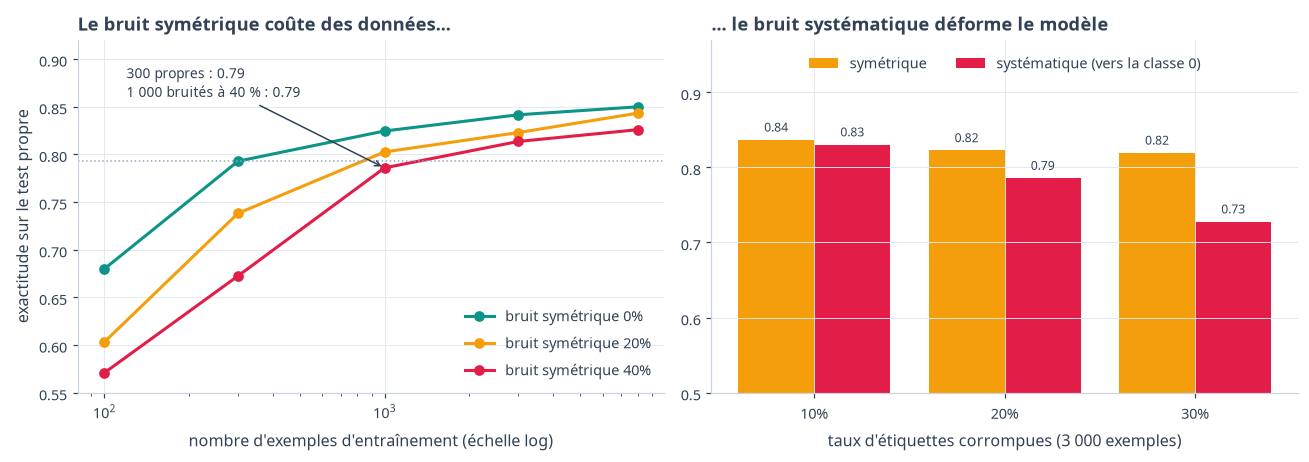

In [6]:
tailles = [100, 300, 1000, 3000, 8000]
taux = [0.0, 0.2, 0.4]
res = {r: [score(X[:n], d8.flip_labels(y, r, K, seed=1)[:n]) for n in tailles] for r in taux}
res_sys = {r: score(X[:3000], d8.flip_labels(y, r, K, seed=1, target=0)[:3000]) for r in [0.1, 0.2, 0.3]}
res_sym = {r: score(X[:3000], d8.flip_labels(y, r, K, seed=1)[:3000]) for r in [0.1, 0.2, 0.3]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
for r, c in zip(taux, [TEAL, AMBER, ROSE]):
    ax.plot(tailles, res[r], "o-", color=c, label=f"bruit symétrique {r:.0%}")
ax.set_xscale("log")
ax.set_xlabel("nombre d'exemples d'entraînement (échelle log)")
ax.set_ylabel("exactitude sur le test propre")
ax.set_title("Le bruit symétrique coûte des données...")
ax.axhline(res[0.0][1], color=GRAY, ls=":", lw=1)
ax.annotate(f"300 propres : {res[0.0][1]:.2f}\n1 000 bruités à 40 % : {res[0.4][2]:.2f}",
            xy=(1000, res[0.4][2]), xytext=(120, 0.86), fontsize=9,
            arrowprops=dict(arrowstyle="->", color=SLATE))
ax.set_ylim(0.55, 0.92)
ax.legend(loc="lower right")
ax = axes[1]
xs = np.arange(3)
ax.bar(xs - 0.2, list(res_sym.values()), 0.4, color=AMBER, label="symétrique")
ax.bar(xs + 0.2, list(res_sys.values()), 0.4, color=ROSE, label="systématique (vers la classe 0)")
annotate_bars(ax, "{:.2f}", fontsize=8)
ax.set_xticks(xs, [f"{r:.0%}" for r in res_sym])
ax.set_xlabel("taux d'étiquettes corrompues (3 000 exemples)")
ax.set_ylim(0.5, 0.97)
ax.set_title("... le bruit systématique déforme le modèle")
ax.legend(loc="upper center", ncol=2)
finish(fig)
plt.show()

Les résultats confirment l'analyse :

- avec un bruit symétrique, les courbes finissent par rejoindre la courbe propre, mais il
  faut **plus d'exemples** pour y arriver : environ 300 exemples propres font aussi bien
  que 1 000 exemples bruités à 40 %. C'est la version miniature du message de LIMA et de
  Yi : la qualité **remplace** de la quantité ;
- avec un bruit systématique, l'écart se creuse vite avec $\varepsilon$ : le modèle
  apprend la consigne mal comprise. C'est pourquoi le livre insiste sur la **cohérence**
  et sur les **consignes d'annotation** (section 6).

> **À retenir.** Six critères définissent une donnée de qualité : pertinente, alignée,
> cohérente, bien formatée, unique, conforme. Le bruit aléatoire se paie en quantité de
> données ; le bruit systématique (consigne mal comprise, biais d'annotateur) se paie en
> qualité du modèle, et aucune quantité ne le compense.